In [1]:
import os
if os.path.basename(os.getcwd()) == "_answers": os.chdir("..")

# Gini prep lab — from scorecard build to IFRS 9 ECL

You're the consultant. A UK lender hands you its unsecured personal-loan book (40,000 loans, originated 2016–2020, monthly performance to Dec 2022) and asks for:

1. a new **application scorecard**, built the way Gini's insights pieces describe (account-data features → tree binning → WoE → MIV selection → transparent logistic, elastic net as challenger), and validated;
2. an **IFRS 9 view**: a forward-looking PD, a SICR threshold set at the point of optimal discrimination, a probability-weighted ECL, and a post-model adjustment if the backtest says you need one.

The data is synthetic, but built so the real traps are in it. Some fields leak. Two are near-duplicates. Something happens to the bureau in mid-2019. Something happens to one segment in 2022. You find them; the checkpoints tell you if you have.

**How to use this**
- Work top to bottom. Each `TODO` cell has a checkpoint after it. ❌ = go and look, not "wrong".
- Each module ends with an **🎤 out-loud question**. Answer it out loud in under a minute. That's the interview.
- Don't open `_answers/` until you're done. `solutions.ipynb` is there when you're stuck for >20 min.
- **If time is short**, the core path is modules 1, 3, 4, 5, 7, 9a, 9c, 9d (~5–6 hours). Modules 2, 6, 8, 9b, 9e deepen it.

| Module | Gini source it mirrors |
|---|---|
| 2 Feature synthesis | *Deep feature synthesis for credit scorecards* |
| 3–5 Binning, WoE, MIV | same (the Revolut pipeline they describe) |
| 6 Elastic net & stability | *Elastic net models for credit risk scorecards* |
| 7 Validation & drift | *TrueVision transition* pieces; SS1/23 |
| 9 SICR, ECL, overlays | *IFRS 9 staging, overlays and judgement*; the two-portfolio IFRS 9 case study |

In [2]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
import checks

pd.set_option("display.width", 160); pd.set_option("display.max_columns", 40)
D = "data/"
loans = pd.read_csv(D + "loans.csv")
perf  = pd.read_parquet(D + "performance.parquet")
acct  = pd.read_csv(D + "account_history.csv")
macro = pd.read_csv(D + "macro.csv")
perf["m"] = pd.PeriodIndex(perf["month"], freq="M")
gini = lambda y, p: 2 * roc_auc_score(y, p) - 1
print(loans.shape, perf.shape, acct.shape, macro.shape)

(40000, 22) (1186540, 7) (240000, 9) (444, 3)


**Data dictionary (short)**

- `loans.csv` — one row per loan. Application fields, plus `close_month / close_reason / default_month` (outcomes — obviously not features).
- `account_history.csv` — 6 monthly current-account summaries per applicant before application (`month_offset` −6…−1).
- `performance.parquet` — loan × month panel: `mob`, `balance`, `dpd_bucket` (0 = up to date, 1 = 30–59, 2 = 60–89, 3 = 90+ = default), `bureau_score` (refreshed monthly, already bridged to one scale).
- `macro.csv` — unemployment history to Dec 2022, then `base / upside / downside` paths to 2032.

Have a poke around before starting: `loans.describe()`, a couple of loans' rows in `perf`, a plot of unemployment.

---
## Module 1 · Target and sample

**Bad** = reached 90+ DPD (`dpd_bucket == 3`) within the first 12 months on book. Loans that prepay before month 12 without defaulting count as good (note in your head that some shops treat them as *indeterminate* — know why).

**Split by time, not at random**: development = vintages 2016-01 to 2018-12; out-of-time (OOT) = 2019-01 to 2020-12.

Why time? Because the question a validator asks is "does it work on loans it hasn't seen, *written later*?" A random split can't answer that.

In [3]:
first12 = perf[perf["mob"] <= 12].groupby("loan_id")["dpd_bucket"].max()
loans["bad"] = (loans["loan_id"].map(first12).fillna(0) >= 3).astype(int)
loans["vintage"] = pd.PeriodIndex(loans["orig_month"], freq="M")
dev = loans[loans["vintage"] <= pd.Period("2018-12", "M")].copy()
oot = loans[loans["vintage"] >  pd.Period("2018-12", "M")].copy()
print(len(dev), dev["bad"].mean().round(4), len(oot), oot["bad"].mean().round(4))
print(loans.groupby(loans["vintage"].dt.year)["bad"].mean().round(4))

24070 0.0408 15930 0.0417
vintage
2016    0.0436
2017    0.0440
2018    0.0346
2019    0.0358
2020    0.0476
Name: bad, dtype: float64


In [4]:
checks.m1(dev, oot)

Checkpoint 1 · target & sample
  ✅ 24,070 dev / 15,930 OOT loans
  ✅ dev bad rate = 0.0408
  ✅ OOT bad rate = 0.0417


True

🎤 *"Your bad rate by vintage year moves around. Is that the borrowers or the economy — and why does it matter for a scorecard vs an IFRS 9 PD?"*

---
## Module 2 · Features from account history (deep feature synthesis, by hand)

DFS stacks three operations over related tables: *entity* features (within one row), *direct* features (pulled across a join), *relational* features (aggregations over many rows). Here the relation is applicant → 6 monthly account rows.

**Task**: build a feature table `feats` (index = `loan_id`) from `acct`. For each numeric column generate at least: mean, max, min, last month (`month_offset == -1`), non-zero month count, and a **trend** (mean of last 3 months − mean of first 3). Add one ratio of your own (e.g. outflow / inflow). Drop constant columns.

Optional: `pip install featuretools` and do it properly with `ft.dfs(..., max_depth=2)` — then notice how fast the candidate count explodes, which is exactly the article's point.

In [5]:
num_cols = ["total_inflow", "total_outflow", "avg_balance", "overdraft_days",
            "returned_dd_count", "gambling_spend", "salary_credit"]
g = acct.groupby("loan_id")
last = acct[acct["month_offset"] == -1].set_index("loan_id")
late = acct[acct["month_offset"] >= -3].groupby("loan_id")
early = acct[acct["month_offset"] <= -4].groupby("loan_id")
feats = pd.DataFrame(index=g.size().index)
for c in num_cols:
    feats[f"{c}_mean"] = g[c].mean()
    feats[f"{c}_max"] = g[c].max()
    feats[f"{c}_min"] = g[c].min()
    feats[f"{c}_last"] = last[c]
    feats[f"{c}_trend"] = late[c].mean() - early[c].mean()
    feats[f"{c}_nonzero_months"] = (acct[c] != 0).groupby(acct["loan_id"]).sum()
feats["outflow_to_inflow_mean"] = feats["total_outflow_mean"] / feats["total_inflow_mean"]
feats = feats.loc[:, feats.nunique() > 1]
print(feats.shape)

(40000, 39)


In [6]:
ACCOUNT_FEATURES = list(feats.columns) if feats is not None else []
dev = dev.join(feats, on="loan_id") if feats is not None else dev
oot = oot.join(feats, on="loan_id") if feats is not None else oot

🎤 *"You've just generated 40 features from 7 columns. A validator says that's a multiple-comparisons problem. What's your answer?"*

---
## Module 3 · Tree binning, WoE, IV

The pipeline in Gini's DFS article: coarse-bin every continuous feature with a **decision tree**, each bin ≥ ~5% of the population, then **merge adjacent bins where the bad-rate trend reverses**. Replace each bin with its **weight of evidence**:

$$\text{WoE}_i = \ln\frac{\%\text{good}_i}{\%\text{bad}_i}, \qquad \text{IV} = \sum_i (\%\text{good}_i - \%\text{bad}_i)\,\text{WoE}_i$$

Missing values get their own bin. Add 0.5 to every cell count so empty bins don't blow up.

First carve a **train / validation** split *inside dev* (70/30, stratified) — fit bins on train only.

**Task**: write `fit_bins(x, y)` → list of edges, `woe_table(x, y, edges)` → DataFrame with `woe` and `iv` per bin, `apply_woe(x, edges, table)` → WoE-transformed series. Then compute IV for every candidate column into a Series `iv`. Categoricals (`channel`, `region`): WoE per category directly.

Rules of thumb: IV < 0.02 useless, 0.1–0.3 medium, 0.3–0.5 strong, **> 0.5 suspicious**.

In [7]:
trn, val = train_test_split(dev, test_size=0.3, stratify=dev["bad"], random_state=1)
NOT_FEATURES = ["loan_id", "orig_month", "vintage", "bad", "close_month", "close_reason",
                "default_month", "postcode_district"]
CATEGORICAL = ["channel", "region"]
candidates = [c for c in dev.columns if c not in NOT_FEATURES + CATEGORICAL]

def fit_bins(x, y, min_frac=0.05, max_bins=8):
    m = x.notna()
    tree = DecisionTreeClassifier(max_leaf_nodes=max_bins,
                                  min_samples_leaf=max(int(min_frac * len(x)), 1), random_state=0)
    tree.fit(x[m].to_frame(), y[m])
    edges = [-np.inf] + sorted(tree.tree_.threshold[tree.tree_.feature >= 0]) + [np.inf]
    while len(edges) > 3:
        rates = y[m].groupby(pd.cut(x[m], edges), observed=False).mean().values
        direction = np.sign(np.corrcoef(np.arange(len(rates)), rates)[0, 1]) or 1
        steps = np.diff(rates) * direction
        if (steps > 0).all():
            break
        edges.pop(int(np.argmin(steps)) + 1)          # merge at the worst reversal
    return edges

def _binned(x, edges):
    return pd.cut(x, edges).astype(str).where(x.notna(), "MISSING")

def woe_table(x, y, edges):
    t = pd.crosstab(_binned(x, edges), y).reindex(columns=[0, 1], fill_value=0) + 0.5
    pg, pb = t[0] / t[0].sum(), t[1] / t[1].sum()
    w = np.log(pg / pb)
    return pd.DataFrame({"n": t.sum(1) - 1, "bad_rate": (t[1] - .5) / (t.sum(1) - 1), "woe": w, "iv": (pg - pb) * w})

def apply_woe(x, edges, table):
    return _binned(x, edges).map(table["woe"]).fillna(0.0).astype(float)

bins, tables = {}, {}
for c in candidates:
    x = trn[c].astype(float)
    bins[c] = fit_bins(x, trn["bad"])
    tables[c] = woe_table(x, trn["bad"], bins[c])
for c in CATEGORICAL:
    t = pd.crosstab(trn[c], trn["bad"]) + 0.5
    pg, pb = t[0] / t[0].sum(), t[1] / t[1].sum()
    tables[c] = pd.DataFrame({"woe": np.log(pg / pb), "iv": (pg - pb) * np.log(pg / pb)}); bins[c] = None
iv = pd.Series({c: tables[c]["iv"].sum() for c in tables}).sort_values(ascending=False)
iv.head(20).round(3)

collections_letters_12m             5.014
district_bad_rate                   1.561
overdraft_days_mean                 0.620
revolving_bal_to_limit              0.524
overdraft_days_max                  0.505
util_ratio                          0.477
credit_score                        0.401
overdraft_days_nonzero_months       0.382
interest_rate                       0.373
avg_balance_min                     0.301
overdraft_days_min                  0.286
overdraft_days_last                 0.277
dti                                 0.209
avg_balance_mean                    0.204
returned_dd_count_mean              0.195
returned_dd_count_max               0.182
num_inquiries_6m                    0.177
outflow_to_inflow_mean              0.172
returned_dd_count_nonzero_months    0.161
avg_balance_last                    0.146
dtype: float64

In [8]:
checks.m3(iv, ACCOUNT_FEATURES)

Checkpoint 3 · binning, WoE, IV
  ✅ IV(credit_score) = 0.4007
  ✅ an account-history feature makes the IV top 10 — the transaction data is pulling its weight
  ℹ️  features with IV > 0.6 (read these before module 4): ['collections_letters_12m', 'district_bad_rate', 'overdraft_days_mean']


True

In [9]:
# helper used from here on: WoE-transform any frame with the dev-fitted bins
def to_woe(frame, cols):
    out = {}
    for c in cols:
        if bins[c] is None:
            out[c] = frame[c].map(tables[c]["woe"]).fillna(0.0)
        else:
            out[c] = apply_woe(frame[c].astype(float), bins[c], tables[c])
    return pd.DataFrame(out, index=frame.index)

Look at `tables["credit_score"]` and `tables["months_since_last_delinq"]` (where does MISSING sit, and why?).

🎤 *"Why WoE-transform at all instead of feeding raw values to the logistic regression?"* (Two reasons from the article, one from operations.)

---
## Module 4 · Leakage and conceptual soundness

Gini's DFS article is explicit that nothing runs unsupervised: a modeller reviews every candidate for **conceptual soundness, business sense, and protected-characteristic proxies** before it goes near the model.

**Task**: go through every feature with IV > 0.3 and ask: *was this known, and computed only from information available, at the decision date?* Investigate the suspicious ones — look at how the values relate to `postcode_district`, to `bad`, to dates. Put anything that fails into `EXCLUDE`, with a one-line reason in a comment.

Also decide on `interest_rate`. There's an argument either way; pick one and write it down.

In [10]:
EXCLUDE = [
    "collections_letters_12m",   # post-origination collections activity: outcome leakage
    "district_bad_rate",         # target-encoded on the full book incl. the loan's own outcome (and OOT):
                                 # leakage + a geographic proxy you'd have to defend under Consumer Duty
    "interest_rate",             # set by the old risk assessment → circular; decision-dependent
]
# evidence for the district one: own-row inclusion makes small districts look predictive
d = dev.groupby("postcode_district").agg(n=("bad", "size"), rate=("district_bad_rate", "first"), act=("bad", "mean"))
print(d.assign(small=d.n < 20).groupby("small")[["rate", "act"]].corr().round(3))

             rate    act
small                   
False rate  1.000  0.788
      act   0.788  1.000
True  rate  1.000  0.711
      act   0.711  1.000


In [11]:
checks.m4(EXCLUDE)

Checkpoint 4 · leakage & conceptual review
  ✅ both planted leaks excluded
  ✅ interest_rate excluded — defensible: it is an output of the old risk assessment


True

🎤 *"Walk me through how you'd catch leakage on a feature set someone else built."*

---
## Module 5 · Marginal information value (MIV) forward selection

Standalone IV ranks features in isolation. MIV asks the better question: **given the model so far, how much new information does this candidate add?**

For candidate feature *x* with bins *i*, using the current model's predicted PDs *p*:
- observed goods/bads per bin: $g_i, b_i$; expected: $\hat b_i = \sum_{j\in i} p_j$, $\hat g_i = n_i - \hat b_i$
- observed WoE and expected WoE per bin, each from the distributions across bins (+0.5 smoothing)
- $\text{MIV} = \sum_i \left(\tfrac{g_i}{G} - \tfrac{b_i}{B}\right)\left(\text{WoE}^{obs}_i - \text{WoE}^{exp}_i\right)$

**Algorithm** (as in the article):
1. Start with the highest-IV eligible feature.
2. Fit logistic on the WoE features; score train.
3. Compute MIV for every remaining candidate whose WoE correlation with every selected feature is < **0.6**.
4. Add the best; stop when the best MIV < **0.02** *or* adding it doesn't improve validation Gini (the article uses both).

Track validation Gini at each step in `history`.

In [12]:
pool = [c for c in iv.index if c not in EXCLUDE and iv[c] >= 0.02]
Wtr, Wva, Woot = to_woe(trn, pool), to_woe(val, pool), to_woe(oot, pool)
ytr, yva, yoot = trn["bad"].values, val["bad"].values, oot["bad"].values

def miv(woe_col, y, p):
    d = pd.DataFrame({"bin": np.round(woe_col.values, 8), "y": y, "p": p})
    a = d.groupby("bin").agg(ob=("y", "sum"), n=("y", "size"), eb=("p", "sum"))
    a["og"], a["eg"] = a["n"] - a["ob"], a["n"] - a["eb"]
    a = a + 0.5
    w_obs = np.log((a.og / a.og.sum()) / (a.ob / a.ob.sum()))
    w_exp = np.log((a.eg / a.eg.sum()) / (a.eb / a.eb.sum()))
    return float(((a.og / a.og.sum() - a.ob / a.ob.sum()) * (w_obs - w_exp)).sum())

def fit_logit(cols):
    return sm.Logit(ytr, sm.add_constant(Wtr[cols])).fit(disp=0)

corr = Wtr.corr().abs()
selected, history = [pool[0]], []
while True:
    model = fit_logit(selected)
    p_tr = model.predict(sm.add_constant(Wtr[selected]))
    history.append((len(selected), selected[-1], gini(yva, model.predict(sm.add_constant(Wva[selected])))))
    eligible = [c for c in pool if c not in selected and corr.loc[c, selected].max() < 0.6]
    if not eligible: break
    scores = {c: miv(Wtr[c], ytr, p_tr) for c in eligible}
    best = max(scores, key=scores.get)
    if scores[best] < 0.02: break
    trial = fit_logit(selected + [best])
    if gini(yva, trial.predict(sm.add_constant(Wva[selected + [best]]))) <= history[-1][2] + 0.001:
        print(f"stop: {best} (MIV {scores[best]:.3f}) doesn't improve validation Gini"); break
    selected.append(best)
history = pd.DataFrame(history, columns=["n", "added", "val_gini"])
val_gini = history["val_gini"].iloc[-1]
print(history.round(4)); print(selected)

stop: loan_amount (MIV 0.033) doesn't improve validation Gini
   n                   added  val_gini
0  1     overdraft_days_mean    0.4514
1  2  revolving_bal_to_limit    0.5101
2  3                     dti    0.5166
3  4            credit_score    0.5246
4  5         avg_balance_min    0.5322
5  6        num_inquiries_6m    0.5334
6  7  outflow_to_inflow_mean    0.5365
['overdraft_days_mean', 'revolving_bal_to_limit', 'dti', 'credit_score', 'avg_balance_min', 'num_inquiries_6m', 'outflow_to_inflow_mean']


In [13]:
checks.m5(selected, val_gini)

Checkpoint 5 · MIV forward selection
  ✅ 7 features selected
  ✅ validation Gini 0.536


True

Which of `util_ratio` / `revolving_bal_to_limit` survived — and why that one? (Hint: numerically, not economically. The elastic net article has something to say about that.)

🎤 *"Why MIV rather than just taking the top 10 by IV?"*

---
## Module 6 · The scorecard, and the elastic net argument

**6a.** Fit the final logistic regression on the WoE features (`params_woe`). With WoE = ln(good/bad) and target = bad, every coefficient should be **negative**. A positive one is a red flag — usually two correlated features fighting.

**6b. The stability experiment** (the elastic net article's opening scenario). On *raw standardised* features `credit_score, util_ratio, revolving_bal_to_limit, dti, num_inquiries_6m, emp_years, homeowner`:
- 200 bootstrap resamples of train;
- each time fit (i) a near-unpenalised logistic (`C=1e6`) and (ii) an elastic net (`penalty="elasticnet", solver="saga", l1_ratio=0.3, C=0.05`);
- record coefficients; build `stab_plain` and `stab_enet` with columns `mean, sd, neg_share` (rows = features).

The true effect of utilisation on default is **positive**. Watch what the plain model thinks.

**6c (stretch).** Run `LogisticRegressionCV` over `l1_ratios` and `Cs` scored on AUC. What does it pick, and why is that *not* the answer to "how much penalty do I need for stability"?

In [14]:
final = fit_logit(selected)
params_woe = final.params
print(final.summary2().tables[1].round(4))

raw_cols = ["credit_score", "util_ratio", "revolving_bal_to_limit", "dti", "num_inquiries_6m", "emp_years", "homeowner"]
Xs = pd.DataFrame(StandardScaler().fit_transform(trn[raw_cols]), columns=raw_cols)
rng = np.random.default_rng(0)
co_plain, co_enet = [], []
for _ in range(200):
    i = rng.integers(0, len(ytr), len(ytr))
    co_plain.append(LogisticRegression(C=1e6, max_iter=3000).fit(Xs.iloc[i], ytr[i]).coef_[0])
    co_enet.append(LogisticRegression(penalty="elasticnet", solver="saga", l1_ratio=0.3, C=0.05,
                                      max_iter=5000).fit(Xs.iloc[i], ytr[i]).coef_[0])
summ = lambda a: pd.DataFrame({"mean": a.mean(), "sd": a.std(), "neg_share": (a < 0).mean()})
stab_plain = summ(pd.DataFrame(co_plain, columns=raw_cols))
stab_enet = summ(pd.DataFrame(co_enet, columns=raw_cols))
print("plain\n", stab_plain.round(3), "\nelastic net\n", stab_enet.round(3))

                         Coef.  Std.Err.        z   P>|z|  [0.025  0.975]
const                  -3.1564    0.0438 -72.1415  0.0000 -3.2422 -3.0707
overdraft_days_mean    -0.3124    0.0772  -4.0483  0.0001 -0.4637 -0.1612
revolving_bal_to_limit -0.4792    0.0683  -7.0191  0.0000 -0.6130 -0.3454
dti                    -0.7717    0.0973  -7.9339  0.0000 -0.9624 -0.5811
credit_score           -0.5243    0.0814  -6.4439  0.0000 -0.6837 -0.3648
avg_balance_min        -0.3050    0.0914  -3.3368  0.0008 -0.4841 -0.1258
num_inquiries_6m       -0.2733    0.0982  -2.7840  0.0054 -0.4657 -0.0809
outflow_to_inflow_mean -0.3145    0.1124  -2.7980  0.0051 -0.5349 -0.0942


plain
                          mean     sd  neg_share
credit_score           -0.345  0.050       1.00
util_ratio             -0.067  0.299       0.61
revolving_bal_to_limit  0.505  0.302       0.04
dti                     0.357  0.035       0.00
num_inquiries_6m        0.139  0.034       0.00
emp_years              -0.028  0.042       0.77
homeowner              -0.044  0.043       0.84 
elastic net
                          mean     sd  neg_share
credit_score           -0.331  0.048      1.000
util_ratio              0.124  0.089      0.000
revolving_bal_to_limit  0.309  0.095      0.000
dti                     0.341  0.034      0.000
num_inquiries_6m        0.135  0.033      0.000
emp_years              -0.022  0.035      0.670
homeowner              -0.039  0.037      0.805


In [15]:
checks.m6(params_woe, stab_plain, stab_enet)

Checkpoint 6 · scorecard + elastic net stability
  ✅ all WoE coefficients negative (WoE = ln(good/bad), target = bad) — signs consistent
  ℹ️  plain logistic: util_ratio coefficient negative in 61% of bootstraps (true effect is positive), sd 0.299
  ℹ️  elastic net:    negative in 0%, sd 0.089
  ✅ elastic net stabilised the correlated pair


True

🎤 *"Your model's Gini is unchanged after recalibration but the top features reshuffled. Is that a problem? What would you do?"*

---
## Module 7 · Validation

Score dev-train, dev-validation and OOT with the **dev-fitted** bins and coefficients (no refitting — that's the point).

**Task**
1. Gini on train / val / OOT, and a 95% bootstrap CI on the OOT Gini (`gini_oot`).
2. **PSI** of the predicted PD between dev-train and OOT, split OOT into vintages before vs from **2019-07** (`psi_post` = dev vs post-Jul-2019). Use dev deciles as the bins.
   $\text{PSI} = \sum (a_i - e_i)\ln(a_i/e_i)$; < 0.1 stable, 0.1–0.25 watch, > 0.25 act.
3. **CSI** for each selected feature (same formula on its dev bins) for post-Jul-2019 → `csi_post` (Series).
4. **Calibration**: mean predicted PD vs actual bad rate for dev, OOT pre-Jul-2019 and post-Jul-2019. `calib_ratio_post` = actual / predicted, post.
5. Plot actual vs predicted by score decile for dev and OOT-post.

Then explain what happened in 2019. Gini wrote two pieces on exactly this kind of event.

Gini train 0.531  val 0.536  OOT 0.483  CI [0.445 0.515]
PSI pre 0.0016
PSI post 0.0468


credit_score              0.5623
revolving_bal_to_limit    0.0012
overdraft_days_mean       0.0005
dti                       0.0004
outflow_to_inflow_mean    0.0004
num_inquiries_6m          0.0003
avg_balance_min           0.0002
dtype: float64
            pred  actual  actual/pred
dev       0.0408  0.0408       1.0000
oot_pre   0.0416  0.0376       0.9021
oot_post  0.0344  0.0432       1.2550


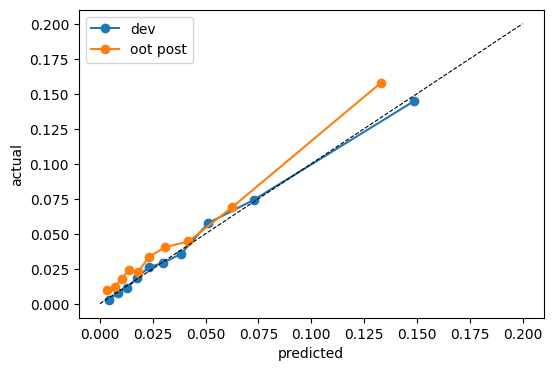

In [16]:
X = lambda W: sm.add_constant(W[selected], has_constant="add")
p_tr, p_va, p_oot = final.predict(X(Wtr)), final.predict(X(Wva)), final.predict(X(Woot))
gini_oot = gini(yoot, p_oot)
rng = np.random.default_rng(1)
bs = [gini(yoot[i], np.asarray(p_oot)[i]) for i in (rng.integers(0, len(yoot), len(yoot)) for _ in range(300))]
print(f"Gini train {gini(ytr, p_tr):.3f}  val {gini(yva, p_va):.3f}  OOT {gini_oot:.3f}  CI {np.percentile(bs, [2.5, 97.5]).round(3)}")

def psi(expected, actual, edges):
    e = np.histogram(expected, edges)[0] / len(expected)
    a = np.histogram(actual, edges)[0] / len(actual)
    e, a = np.clip(e, 1e-4, None), np.clip(a, 1e-4, None)
    return float(((a - e) * np.log(a / e)).sum())

post = (oot["vintage"] >= pd.Period("2019-07", "M")).values
edges = np.unique(np.quantile(p_tr, np.linspace(0, 1, 11))); edges[0], edges[-1] = -np.inf, np.inf
print("PSI pre", round(psi(p_tr, p_oot[~post], edges), 4))
psi_post = psi(p_tr, p_oot[post], edges); print("PSI post", round(psi_post, 4))

def csi(c, mask):
    e = _binned(trn[c].astype(float), bins[c]) if bins[c] else trn[c]
    a = _binned(oot[c].astype(float), bins[c])[mask] if bins[c] else oot[c][mask]
    e, a = e.value_counts(normalize=True), a.value_counts(normalize=True).reindex(e.value_counts().index).fillna(1e-4)
    return float(((a - e) * np.log(a / e)).sum())
csi_post = pd.Series({c: csi(c, post) for c in selected}).sort_values(ascending=False)
print(csi_post.round(4))

cal = pd.DataFrame({
    "pred": [p_tr.mean(), p_oot[~post].mean(), p_oot[post].mean()],
    "actual": [ytr.mean(), yoot[~post].mean(), yoot[post].mean()]}, index=["dev", "oot_pre", "oot_post"])
cal["actual/pred"] = cal["actual"] / cal["pred"]; print(cal.round(4))
calib_ratio_post = cal.loc["oot_post", "actual/pred"]

fig, ax = plt.subplots(figsize=(6, 4))
for name, y_, p_ in [("dev", ytr, p_tr), ("oot post", yoot[post], np.asarray(p_oot)[post])]:
    dd = pd.DataFrame({"y": y_, "p": p_}); dd["dec"] = pd.qcut(dd["p"], 10, labels=False)
    gg = dd.groupby("dec").mean(); ax.plot(gg["p"], gg["y"], "o-", label=name)
ax.plot([0, .2], [0, .2], "k--", lw=.8); ax.set_xlabel("predicted"); ax.set_ylabel("actual"); ax.legend(); plt.show()

In [17]:
checks.m7(gini_oot, psi_post, csi_post, calib_ratio_post)

Checkpoint 7 · validation
  ✅ OOT Gini = 0.4831
  ℹ️  score PSI (dev vs OOT from Jul-2019) = 0.047 — note what it does and doesn't tell you
  ✅ CSI flags credit_score (0.56) even though the score PSI looked calm
  ✅ post-Jul-2019 actual/predicted = 1.25 → under-prediction despite a healthy Gini


True

Things to notice and be ready to say:
- The **score PSI looks calm**, yet one input's CSI is screaming. A shifted input can be diluted in the score distribution (coarse bins cap it, other features dominate) while still breaking calibration. Monitor inputs, not just outputs.
- Gini barely moved after mid-2019. Calibration did. *Discrimination and calibration are different tests* — a monitoring pack that only tracks Gini would have missed this.
- Which feature's CSI explains it? Look at `credit_score` distributions by half-year. What changed, and what's the fix (re-bin? bridge? recalibrate the intercept? redevelop)?
- OOT pre-Jul-2019 *over*-predicts. Why? (Look at unemployment in 2019–20 vs 2016–18.)

🎤 *"Your OOT Gini is fine but the model under-predicts by 25%. Approve it?"*

---
## Module 8 · Points scaling (short)

Convert PD to a points score: **600 points at good:bad odds of 50:1, 20 points to double the odds (PDO)**.

$\text{score} = \text{offset} + \text{factor}\cdot\ln(\text{odds}_{good:bad})$, with factor = PDO / ln 2.

Write `score_fn(p)` (vectorised). Then, for one applicant, show the points contributed by each feature — that's the table a credit committee actually reads.

In [18]:
factor = 20 / np.log(2); offset = 600 - factor * np.log(50)
score_fn = lambda p: offset + factor * np.log((1 - p) / p)
# per-feature points (intercept spread evenly)
k = len(selected); b0 = final.params["const"]
pts = pd.DataFrame({c: -factor * final.params[c] * Wtr[c] for c in selected}) + (offset - factor * b0) / k
print(pts.iloc[0].round(1), "\ntotal", pts.iloc[0].sum().round(1), "check", score_fn(np.array([p_tr.iloc[0]]))[0].round(1))

overdraft_days_mean       88.1
revolving_bal_to_limit    83.9
dti                       74.7
credit_score              95.3
avg_balance_min           83.1
num_inquiries_6m          86.8
outflow_to_inflow_mean    84.2
Name: 14185, dtype: float64 
total 596.1 check 596.1


In [19]:
checks.m8(score_fn)

Checkpoint 8 · points scaling
  ✅ 600 points at 50:1, 20 points to double the odds


True

---
## Module 9 · IFRS 9: PD, SICR, ECL, overlays

You now switch from "will this applicant go bad?" to "what loss do we expect on the book we hold today?". Gini's line is that fitting the model is the easy part; **staging, scenario weights and overlays are where the judgement — and the audit scrutiny — sits**.

### 9a · A forward-looking 12-month PD

Build quarter-end **snapshots** from 2016-12 to 2020-12 of every loan not in default (`dpd_bucket < 3`). For each, `def12` = defaults (first reaches `dpd_bucket == 3`) in the next 12 months. Attach `dti` from loans and `unemp_fwd12` = **average unemployment over the next 12 months** (realised, for training — at reporting time you'll plug in a scenario path; that's what makes it forward-looking).

Fit a logistic: `def12 ~ bureau_score + C(dpd_bucket) + mob_c + I(mob_c**2) + dti + unemp_fwd12` with `mob_c = min(mob, 48)`.

Why stop at 2020-12 snapshots? Because you'll need 2022 for a backtest in 9e.

In [20]:
hist_u = macro[macro["type"] == "history"]
hist_u = pd.Series(hist_u["unemployment"].values, index=pd.PeriodIndex(hist_u["month"], freq="M"))
first_def = perf[perf["dpd_bucket"] == 3].groupby("loan_id")["m"].min()
L = loans.set_index("loan_id")

def snapshot(date):
    d = pd.Period(date, "M")
    s = perf[(perf["m"] == d) & (perf["dpd_bucket"] < 3)].copy()
    fd = s["loan_id"].map(first_def)
    s["def12"] = ((fd > d) & (fd <= d + 12)).astype(int)
    s["unemp_fwd12"] = hist_u[(hist_u.index > d) & (hist_u.index <= d + 12)].mean()
    s["dti"] = s["loan_id"].map(L["dti"])
    s["mob_c"] = np.minimum(s["mob"], 48)
    s["snap"] = str(d)
    return s

snaps = pd.concat([snapshot(str(p)) for p in pd.period_range("2016-12", "2020-12", freq="Q").asfreq("M", "end")])
pd12 = smf.logit("def12 ~ bureau_score + C(dpd_bucket) + mob_c + I(mob_c**2) + dti + unemp_fwd12", snaps).fit(disp=0)
pd12_gini = gini(snaps["def12"], pd12.predict(snaps))
print(len(snaps), snaps["def12"].mean().round(4), round(pd12_gini, 3)); print(pd12.params.round(4))

275082 0.0561 0.575
Intercept             2.0620
C(dpd_bucket)[T.1]    2.3878
C(dpd_bucket)[T.2]    3.6845
bureau_score         -0.0107
mob_c                -0.0101
I(mob_c ** 2)        -0.0004
dti                   2.3964
unemp_fwd12           0.3057
dtype: float64


In [21]:
checks.m9a(pd12.params if pd12 is not None else None, pd12_gini)

Checkpoint 9a · 12-month behavioural PD
  ✅ unemployment coefficient 0.306 > 0
  ✅ snapshot Gini = 0.5749


True

### 9b · From 12-month PD to a lifetime PD term structure

Simplest defensible extrapolation (state it as an assumption):
- Year 1: 12m PD with today's `dpd_bucket`, `mob`, and the scenario's average unemployment for months 1–12.
- Year *k* ≥ 2: same model, `dpd_bucket = 0` (survivors have cured), `mob + 12(k−1)`, scenario unemployment for that year.
- Convert each year's PD to a flat **monthly hazard** $h = 1-(1-PD)^{1/12}$; zero beyond remaining term.

Write `monthly_hazards(score, dpd, mob, dti, rem, upath)` → array (n, H); `lifetime_pd(hz)`; `annualise(lpd, rem)`.

Why annualise? SICR compares PD *now* (remaining life R) with PD *at origination* (full term). Different horizons aren't comparable; annualised ones are.

In [22]:
b = pd12.params if pd12 is not None else None
def pd12_from(score, dpd, mob, dti, u):
    mob = np.minimum(mob, 48)
    lp = (b["Intercept"] + b["bureau_score"] * score + b["C(dpd_bucket)[T.1]"] * (dpd == 1)
          + b["C(dpd_bucket)[T.2]"] * (dpd == 2) + b["mob_c"] * mob + b["I(mob_c ** 2)"] * mob ** 2
          + b["dti"] * dti + b["unemp_fwd12"] * u)
    return 1 / (1 + np.exp(-lp))

def monthly_hazards(score, dpd, mob, dti, rem, upath):
    n, H = len(score), int(np.max(rem))
    up = np.broadcast_to(np.asarray(upath, float)[..., :H], (n, H))
    hz = np.zeros((n, H))
    for k in range(int(np.ceil(H / 12))):
        lo, hi = 12 * k, min(12 * k + 12, H)
        p = pd12_from(score, dpd if k == 0 else np.zeros(n), mob + 12 * k, dti, up[:, lo:hi].mean(1))
        hz[:, lo:hi] = (1 - (1 - p) ** (1 / 12))[:, None]
    hz[np.arange(H)[None, :] >= np.asarray(rem)[:, None]] = 0
    return hz

lifetime_pd = lambda hz: 1 - np.prod(1 - hz, axis=1)
annualise = lambda lpd, rem: 1 - (1 - lpd) ** (12 / np.maximum(rem, 1))

In [23]:
checks.m9b(lifetime_pd, annualise)

Checkpoint 9b · lifetime PD mechanics
  ✅ lifetime PD from monthly hazards = 0.2143
  ✅ annualised = 0.1136


True

### 9c · SICR at the point of optimal discrimination

The Gini case study reset SICR thresholds *"against the point of optimal discrimination rather than inherited"*. Here's how you'd do that.

1. **Origination comparator** per loan: annualised lifetime PD using `bureau_score` at `mob == 1`, `dpd = 0`, `mob = 1`, `rem = term`, unemployment flat at its origination-month value → `ann_pd0`.
2. At each calibration date (2018-12, 2019-06, 2019-12, 2020-06, 2020-12): annualised lifetime PD now (`ann_pd`, unemployment flat at that month's value), `ratio = ann_pd / ann_pd0`, and outcome `def12`.
3. SICR flag = `(ratio > k AND ann_pd − ann_pd0 > a) OR dpd_bucket ≥ 1` (the last bit is the 30-DPD backstop).
4. Grid `k ∈ {1.1, 1.2, 1.3, 1.4, 1.5, 1.75, 2, 2.5, 3, 4}`, `a ∈ {0, 0.005, 0.01, 0.02}`. For each: TPR (share of next-year defaulters flagged), FPR, **Youden J = TPR − FPR**, Stage 2 share. → `sicr_grid`.
5. How many backstop cases does the quantitative trigger already catch?

In [24]:
first = perf[perf["mob"] == 1].set_index("loan_id")
L["score0"] = first["bureau_score"]
L["u0"] = pd.PeriodIndex(L["orig_month"], freq="M").map(hist_u)
term = L["term_months"].values.astype(float)
hz0 = monthly_hazards(L["score0"].values, np.zeros(len(L)), np.ones(len(L)), L["dti"].values, term,
                      L["u0"].values[:, None] * np.ones((1, 60)))
L["ann_pd0"] = annualise(lifetime_pd(hz0), term)

def staged(date, upath=None):
    d = pd.Period(date, "M")
    s = perf[(perf["m"] == d) & (perf["dpd_bucket"] < 3)].join(L[["term_months", "dti", "ann_pd0", "interest_rate"]], on="loan_id")
    s["rem"] = (s["term_months"] - s["mob"]).clip(lower=1)
    up = np.full(60, hist_u[d]) if upath is None else upath
    hz = monthly_hazards(s["bureau_score"].values, s["dpd_bucket"].values, s["mob"].values.astype(float),
                         s["dti"].values, s["rem"].values.astype(float), up)
    s["ann_pd"] = annualise(lifetime_pd(hz), s["rem"].values)
    s["ratio"] = s["ann_pd"] / s["ann_pd0"]
    fd = s["loan_id"].map(first_def); s["def12"] = ((fd > d) & (fd <= d + 12)).astype(int)
    return s

cal_set = pd.concat([staged(x) for x in ["2018-12", "2019-06", "2019-12", "2020-06", "2020-12"]])
rows = []
for k in [1.1, 1.2, 1.3, 1.4, 1.5, 1.75, 2, 2.5, 3, 4]:
    for a in [0.0, 0.005, 0.01, 0.02]:
        f = ((cal_set["ratio"] > k) & (cal_set["ann_pd"] - cal_set["ann_pd0"] > a)) | (cal_set["dpd_bucket"] >= 1)
        tpr, fpr = f[cal_set["def12"] == 1].mean(), f[cal_set["def12"] == 0].mean()
        rows.append((k, a, tpr, fpr, tpr - fpr, f.mean()))
sicr_grid = pd.DataFrame(rows, columns=["k", "abs", "tpr", "fpr", "youden", "stage2_share"])
print(sicr_grid.sort_values("youden", ascending=False).head(8).round(4))
best = sicr_grid.sort_values("youden", ascending=False).iloc[0]
quant = (cal_set["ratio"] > best.k) & (cal_set["ann_pd"] - cal_set["ann_pd0"] > best["abs"])
print("backstop cases already caught by the quantitative test:", quant[cal_set["dpd_bucket"] >= 1].mean().round(3))

      k    abs     tpr     fpr  youden  stage2_share
2   1.1  0.010  0.4618  0.1319  0.3299        0.1501
1   1.1  0.005  0.5105  0.1875  0.3230        0.2054
6   1.2  0.010  0.4443  0.1265  0.3179        0.1441
3   1.1  0.020  0.4038  0.0870  0.3168        0.1046
7   1.2  0.020  0.4006  0.0864  0.3142        0.1038
10  1.3  0.010  0.4262  0.1153  0.3109        0.1326
11  1.3  0.020  0.3940  0.0844  0.3096        0.1016
15  1.4  0.020  0.3869  0.0813  0.3057        0.0982
backstop cases already caught by the quantitative test: 1.0


In [25]:
checks.m9c(sicr_grid)

Checkpoint 9c · SICR threshold
  ✅ best Youden J = 0.3299
  ✅ Stage 2 share at the optimum 15.0%
  ℹ️  your optimum: k = 1.1, absolute floor = 0.010. Now argue whether you'd actually use it.


True

Now the judgement bit. The Youden optimum likely sits at a *small* relative multiple with an absolute floor doing the real work. Ask yourself:
- Is "10% higher than at origination" a *significant* increase in any sense a committee would accept? What does the absolute floor buy you?
- Pivot `sicr_grid` into a k × a table of Youden. How flat is the surface? If several thresholds are within noise, what else would you optimise for (Stage 2 volatility quarter to quarter, stability across calibration dates, share of defaulters that pass through Stage 2 before default)?
- More than half of next-year defaulters are *not* flagged. Why is that inherent in a **relative** test? (Think: a loan that was risky at origination and stayed risky.)

🎤 *"How would you set a SICR threshold if you were rebuilding it from scratch — and how would you defend it to the auditor?"*

### 9d · Probability-weighted ECL at 31 Dec 2022

Book = every loan in `perf` at 2022-12.
- **Stage 3**: `dpd_bucket == 3`. ECL = LGD × balance.
- **Stage 1 / 2**: stage using your chosen (k, a) on the **probability-weighted** lifetime PD (weights base 50%, upside 20%, downside 30%) vs `ann_pd0`, plus the backstop.
- For each scenario path from `macro` (2023-01 onwards):
  - monthly hazards → marginal default probability in month *t*: $S_{t-1}\,h_t$
  - **EAD**: scheduled amortising balance at the start of month *t* (from current balance, `interest_rate`, remaining term) × $(1-\text{CPR})^{t-1}$ with monthly prepayment CPR = 1.1% (stretch: estimate it from `close_reason`)
  - **LGD** = 72% (unsecured, given)
  - **discount** at the loan's EIR: $(1 + r/12)^{-t}$
  - Stage 1 sums months 1–12, Stage 2 the whole remaining life.
- ECL = Σ weight × scenario ECL.

Produce `ecl_summary` (index = stage; columns `n`, `gca`, `ecl`) and `ecl_by_scenario` (dict base/upside/downside → total ECL).

In [26]:
LGD, CPR = 0.72, 0.011
WEIGHTS = {"base": 0.5, "upside": 0.2, "downside": 0.3}
K_SICR, A_SICR = best.k, best["abs"]

rep = pd.Period("2022-12", "M")
book = perf[perf["m"] == rep].join(L[["term_months", "dti", "ann_pd0", "interest_rate"]], on="loan_id")
book["rem"] = (book["term_months"] - book["mob"]).clip(lower=1)
pb = book[book["dpd_bucket"] < 3].copy()
n, rem, r = len(pb), pb["rem"].values.astype(float), pb["interest_rate"].values / 12
H = int(rem.max()); t = np.arange(1, H + 1)
pmt = pb["balance"].values * r / (1 - (1 + r) ** (-rem))
sched = pb["balance"].values[:, None] * (1 + r[:, None]) ** t - pmt[:, None] * ((1 + r[:, None]) ** t - 1) / r[:, None]
sched = np.clip(np.where(t[None, :] <= rem[:, None], sched, 0), 0, None)
ead = np.concatenate([pb["balance"].values[:, None], sched[:, :-1]], axis=1) * (1 - CPR) ** (t[None, :] - 1)
disc = (1 + r[:, None]) ** (-t[None, :])

paths = {s: macro.loc[macro["type"] == s, "unemployment"].values for s in WEIGHTS}
el12, ellife, lpd = {}, {}, {}
for s, up in paths.items():
    hz = monthly_hazards(pb["bureau_score"].values, pb["dpd_bucket"].values, pb["mob"].values.astype(float),
                         pb["dti"].values, rem, up)
    surv_prev = np.concatenate([np.ones((n, 1)), np.cumprod(1 - hz, axis=1)[:, :-1]], axis=1)
    el = surv_prev * hz * LGD * ead * disc
    el12[s], ellife[s], lpd[s] = el[:, :12].sum(1), el.sum(1), lifetime_pd(hz)

pb["ann_pd"] = annualise(sum(WEIGHTS[s] * lpd[s] for s in WEIGHTS), rem)
pb["ratio"] = pb["ann_pd"] / pb["ann_pd0"]
pb["stage"] = np.where(((pb["ratio"] > K_SICR) & (pb["ann_pd"] - pb["ann_pd0"] > A_SICR)) | (pb["dpd_bucket"] >= 1), 2, 1)
for s in WEIGHTS:
    pb[f"ecl_{s}"] = np.where(pb["stage"] == 1, el12[s], ellife[s])
s3 = book[book["dpd_bucket"] == 3].copy(); s3["stage"] = 3
for s in WEIGHTS: s3[f"ecl_{s}"] = LGD * s3["balance"]
allb = pd.concat([pb, s3])
allb["ecl"] = sum(WEIGHTS[s] * allb[f"ecl_{s}"] for s in WEIGHTS)
ecl_by_scenario = {s: allb[f"ecl_{s}"].sum() for s in WEIGHTS}
ecl_summary = allb.groupby("stage").agg(n=("loan_id", "size"), gca=("balance", "sum"), ecl=("ecl", "sum"))
ecl_summary["coverage"] = ecl_summary["ecl"] / ecl_summary["gca"]
print(ecl_summary.round(3)); print({k: round(v) for k, v in ecl_by_scenario.items()})

          n          gca         ecl  coverage
stage                                         
1      5917  18301928.65  188278.157     0.010
2      1168   3740514.62  305230.794     0.082
3       290   1207783.27  869603.954     0.720
{'base': 1325926, 'upside': 1296393, 'downside': 1469571}


In [27]:
checks.m9d(ecl_summary, ecl_by_scenario)

Checkpoint 9d · ECL
  ✅ coverage rises by stage: 1.0%, 8.2%, 72.0%
  ✅ total ECL £1,363,113
  ✅ probability-weighted ECL is 2.8% above base — the non-linearity


True

Extra things to try, each a likely interview probe:
- Re-stage on **base only** instead of weighted PD. How much moves between stages, and which is more defensible?
- Change the weights to 40/20/40. How sensitive is total ECL? That sensitivity *is* the disclosure.
- Double LGD's contribution in the downside (LGDs are cyclical too). Does it matter more for Stage 1 or 2?

🎤 *"Why can't you just run the base-case forecast and book that?"*

### 9e · Backtest, and do you need an overlay?

Take the **2021-12** snapshot (outside your training window). Predict 12m PD using the *realised* 2022 unemployment (so macro error is switched off — any miss is the model's). Compare predicted vs actual default rate by every driver you can band: `dti` (≤0.3, 0.3–0.4, >0.4), bureau score band, mob band, region.

If a segment is materially under-predicted:
- name it (`overlay_segment`, a short string),
- `overlay_uplift` = actual / predicted for that segment,
- size the post-model adjustment on the 2022-12 book: (uplift − 1) × modelled ECL for that segment in Stages 1–2,
- write three sentences a committee would accept: **what risk** the model misses, **why** (what's happened in the world), and the **release trigger**.

The Gini article's line on overlays: targeted, quantified, documented, and paired with a commitment to fix the model.

In [28]:
bt = snapshot("2021-12")
bt["p"] = pd12.predict(bt)
bt["dti_band"] = pd.cut(bt["dti"], [0, .3, .4, 1])
bt["score_band"] = pd.qcut(bt["bureau_score"], 4)
for col in ["dti_band", "score_band"]:
    tb = bt.groupby(col, observed=True).agg(n=("p", "size"), pred=("p", "mean"), actual=("def12", "mean"))
    tb["actual/pred"] = tb["actual"] / tb["pred"]; print(tb.round(4), "\n")
seg = bt["dti"] > 0.4
overlay_segment = "dti > 0.4"
overlay_uplift = bt.loc[seg, "def12"].mean() / bt.loc[seg, "p"].mean()
hi = (allb["dti"] > 0.4) & (allb["stage"] < 3)
pma = (overlay_uplift - 1) * allb.loc[hi, "ecl"].sum()
print(f"uplift ×{overlay_uplift:.2f}  PMA £{pma:,.0f}  ({pma / allb['ecl'].sum():.1%} of modelled ECL)")
# Committee note:
# Risk: borrowers with DTI > 40% are defaulting ~1.3x faster than the model predicts through 2022, while lower-DTI
#   segments are on model — consistent with cost-of-living pressure squeezing already-stretched budgets, which neither
#   unemployment nor the bureau score captures.
# Size: (uplift − 1) × modelled Stage 1–2 ECL for the segment.
# Release: when two consecutive quarterly backtests show the segment within ±10% of model, or when a redeveloped PD
#   with an affordability / inflation driver goes live (target: next annual model cycle).

               n    pred  actual  actual/pred
dti_band                                     
(0.0, 0.3]  7085  0.0328  0.0335       1.0195
(0.3, 0.4]  2715  0.0449  0.0508       1.1316
(0.4, 1.0]  3214  0.0652  0.0815       1.2502 

                     n    pred  actual  actual/pred
score_band                                         
(299.999, 620.0]  3291  0.1038  0.1115       1.0748
(620.0, 671.0]    3218  0.0359  0.0447       1.2451
(671.0, 714.0]    3261  0.0215  0.0261       1.2102
(714.0, 911.0]    3244  0.0113  0.0126       1.1195 

uplift ×1.25  PMA £50,686  (3.7% of modelled ECL)


In [29]:
checks.m9e(overlay_segment, overlay_uplift if overlay_uplift is not None else 0)

Checkpoint 9e · backtest & overlay
  ✅ segment: dti > 0.4
  ✅ uplift ×1.25


True

🎤 *"Your overlay is now 15% of ECL and has been in place for three quarters. What's the conversation with the auditor?"*

---
## Module 10 · Take it to real data (your Freddie Mac sample)

Everything above ports to the Freddie Mac single-family sample you've got in DuckDB, and that's the version worth talking about in the interview. Mapping (check names against your schema — these are descriptive, not exact):

| Here | Freddie Mac |
|---|---|
| `loans` | origination file: credit score, original LTV, original DTI, occupancy, purpose, channel, property type, first-time buyer, MI %, number of borrowers |
| `perf` | monthly performance: loan age, current UPB, current delinquency status, zero-balance code / date |
| `bad` | delinquency status ≥ 3 (90+) within 12–24 months of first payment |
| bureau refresh | not available → SICR has to run on delinquency, LTV (index the house price) and model PD; that limitation is itself a good talking point |
| LGD | net sale proceeds / expenses / MI recoveries on zero-balance loans → you can build a real LGD, including **time to sale** (the case study's reopened assumption) |

A 2007 vintage is the crisis book. Build the scorecard on 2005–06 vintages and run it OOT on 2007: that is a validation story with real teeth.

```sql
-- template: 12-month bad flag per loan (rename columns to match your table)
CREATE OR REPLACE TABLE target AS
SELECT loan_id,
       MAX(CASE WHEN loan_age <= 12 AND TRY_CAST(delinquency_status AS INT) >= 3 THEN 1 ELSE 0 END) AS bad12
FROM perf
GROUP BY loan_id;
```